# Silver twisted bilayer: finite 50 × 50 layers, direct coupled dipoles

Each layer is a **50 × 50 primitive-lattice patch** (2,500 spheres), giving 5,000 dipoles and 15,000 complex unknowns. This is not a 50 × 50 tiling of the five-particle periodic supercell. The two patch centroids coincide in the xy plane; their primitive vectors reproduce the original notebook's 36.87° relative twist. Radius = 50 nm, lattice spacing = 200 nm, layer separation = 100 nm, vacuum host, x-polarized light propagating along +z.

The solver explicitly sums **all distinct particle pairs in free space**, with open boundaries, no Ewald summation, no periodic images, and no distance cutoff. GMRES solves the direct coupled-dipole equations without allocating the full dense 15,000 × 15,000 matrix (~3.6 GB). Pair blocks bound temporary memory, but each iteration still requires O(N²) work. A complete spectrum can take substantial time; start with a few wavelengths if desired. Reusable numerical code lives in `src/cdm_ewald/finite_direct.py`.

With lengths scaled by the sphere radius R and polarizability including 4π:

\[
\mathbf p_i=\alpha\left(\mathbf E_{\rm inc,i}+\sum_{j\ne i}\mathbf G_{ij}\mathbf p_j\right),\quad
\mathbf G(\mathbf r)=\frac{e^{ikr}}{4\pi r^3}\left[((kr)^2+ikr-1)\mathbf I+(3-3ikr-(kr)^2)\hat{\mathbf r}\hat{\mathbf r}\right].
\]

The electric-dipole Mie polarizability is the same as in the original notebook, so its radiation reaction is already included and no additional self term is added.

For a finite array, use the optical theorem:
\[
C_{\rm ext}=R^2\frac{k}{|E_0|^2}\operatorname{Im}\sum_i\mathbf E_{\rm inc,i}^{*}\cdot\mathbf p_i.
\]
Here k is dimensionless. We report C_ext in nm² and C_ext / [2500 a²], using **one layer's nominal area** as a reference. This normalized cross section is not a bounded transmission loss or the periodic notebook's `1 - |t|²`. See the [DDA formulation and optical theorem](https://pmc.ncbi.nlm.nih.gov/articles/PMC11990789/); its Gaussian-unit polarizability differs by 4π from the convention used here.

In [1]:
from pathlib import Path
import logging
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

# Works when opened from the repository root or its notebook directory.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/cdm_ewald/finite_direct.py").exists()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the particle_mesh_method repository")
sys.path.insert(0, str(REPO_ROOT / "src"))
from cdm_ewald.finite_direct import (
    twisted_bilayer, mie_polarizability, solve_direct, extinction_cross_section,
)

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s")
logger = logging.getLogger("silver_finite_direct")

In [2]:
SIDE = 50
RADIUS_NM = 50.0
SPACING_NM = 200.0
SEPARATION_NM = 100.0
BLOCK_SIZE = 64
RTOL = 1e-6
RESTART = 60
MAX_CYCLES = 100
# None uses the original spectral grid plus its 470–490 nm refinement.
# For an initial run, set e.g. np.array([470.0, 480.0, 490.0]).
WAVELENGTHS_NM = None
OUTPUT_DIR = REPO_ROOT / "outputs" / "silver_twisted_bilayer_direct_50x50"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

optical = np.genfromtxt(
    REPO_ROOT / "test/bilayers/silver_optical_data.csv", delimiter=",", names=True,
)
order = np.argsort(optical["lambda_real"])
source_nm = optical["lambda_real"][order] * 1e9
source_eps = optical["e1"][order] + 1j * optical["e2"][order]
wavelength_nm = (
    np.unique(np.concatenate((source_nm, np.arange(470 / 50, 490 / 50, 0.1) * 50)))
    if WAVELENGTHS_NM is None else np.sort(np.asarray(WAVELENGTHS_NM, dtype=float))
)
if (wavelength_nm.ndim != 1 or wavelength_nm.size == 0
        or not np.isfinite(wavelength_nm).all()
        or wavelength_nm.min() < source_nm.min()
        or wavelength_nm.max() > source_nm.max()):
    raise ValueError("Choose a nonempty wavelength array within the silver data range")
epsilon = np.interp(wavelength_nm, source_nm, source_eps.real) + 1j * np.interp(
    wavelength_nm, source_nm, source_eps.imag,
)
k_values = 2 * np.pi * RADIUS_NM / wavelength_nm
alpha_values = mie_polarizability(k_values, epsilon)
positions_nm = twisted_bilayer(SIDE, SPACING_NM, SEPARATION_NM)
positions = positions_nm / RADIUS_NM
particles_per_layer = SIDE**2
reference_area_nm2 = particles_per_layer * SPACING_NM**2
logger.info("%d particles, %d wavelengths", len(positions), len(wavelength_nm))

/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/finite_direct.py:37: RuntimeWarning: divide by zero encountered in matmul
  np.column_stack((indices @ bottom.T, np.zeros(side**2))),
/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/finite_direct.py:37: RuntimeWarning: overflow encountered in matmul
  np.column_stack((indices @ bottom.T, np.zeros(side**2))),
/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/finite_direct.py:37: RuntimeWarning: invalid value encountered in matmul
  np.column_stack((indices @ bottom.T, np.zeros(side**2))),
/Users/doggy/Documents/00_Research/00_projects_ongoing/00_mpm_long_range/01_Simulations/optics/particle_mesh_method/src/cdm_ewald/finite_direct.py:38: RuntimeWarning: divide by zero encountered in matmul
  np.column

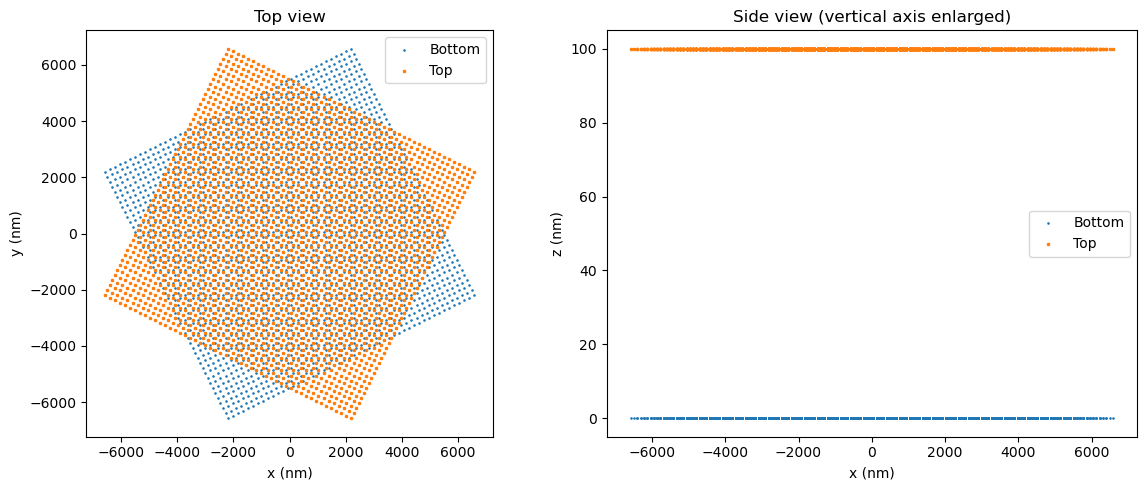

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label, layer, marker in (
    ("Bottom", slice(0, particles_per_layer), "."),
    ("Top", slice(particles_per_layer, None), "x"),
):
    xyz = positions_nm[layer]
    axes[0].scatter(xyz[:, 0], xyz[:, 1], s=3, marker=marker, label=label)
    axes[1].scatter(xyz[:, 0], xyz[:, 2], s=3, marker=marker, label=label)
axes[0].set(xlabel="x (nm)", ylabel="y (nm)", title="Top view", aspect="equal")
axes[1].set(xlabel="x (nm)", ylabel="z (nm)", title="Side view (vertical axis enlarged)")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## Solve the spectrum

Run the next cell to calculate every dipole at every wavelength. Incident amplitude is 1, so the stored dipoles are p_physical / (ε₀ E₀ R³). Each completed wavelength is saved immediately, along with geometry, polarizability, residual, and iteration count. A convergence failure raises an exception; preceding wavelength files remain available. Re-running recalculates and overwrites those files. The previous wavelength's solution provides the next initial guess.

In [4]:
dipoles = np.empty((len(wavelength_nm), len(positions), 3), dtype=complex)
extinction_nm2 = np.empty(len(wavelength_nm))
relative_residuals = np.empty(len(wavelength_nm))
iteration_counts = np.empty(len(wavelength_nm), dtype=int)
previous = None
for index, (wavelength, k, alpha) in enumerate(zip(wavelength_nm, k_values, alpha_values)):
    started = time.perf_counter()
    incident = np.exp(1j * k * positions[:, 2, None]) * np.array([1.0, 0.0, 0.0])
    solution = solve_direct(
        positions, k, alpha, incident, block_size=BLOCK_SIZE, rtol=RTOL,
        restart=RESTART, maxiter=MAX_CYCLES, initial_dipoles=previous,
    )
    dipoles[index] = solution.dipoles
    previous = solution.dipoles
    extinction_nm2[index] = RADIUS_NM**2 * extinction_cross_section(k, incident, previous)
    relative_residuals[index] = solution.relative_residual
    iteration_counts[index] = solution.iterations
    np.savez_compressed(
        OUTPUT_DIR / f"wavelength_{index:04d}.npz",
        wavelength_nm=wavelength, positions_nm=positions_nm, dipoles=previous,
        extinction_nm2=extinction_nm2[index], alpha=alpha, k=k,
        radius_nm=RADIUS_NM, reference_area_nm2=reference_area_nm2,
        relative_residual=solution.relative_residual, iterations=solution.iterations,
    )
    logger.info(
        "%.2f nm: C_ext=%.6g nm², residual=%.2e, iterations=%d, %.1f s",
        wavelength, extinction_nm2[index], solution.relative_residual,
        solution.iterations, time.perf_counter() - started,
    )

normalized_extinction = extinction_nm2 / reference_area_nm2
np.savez_compressed(
    OUTPUT_DIR / "spectrum_and_dipoles.npz", wavelength_nm=wavelength_nm,
    positions_nm=positions_nm, dipoles=dipoles, extinction_nm2=extinction_nm2,
    normalized_extinction=normalized_extinction, relative_residuals=relative_residuals,
    iteration_counts=iteration_counts, radius_nm=RADIUS_NM,
    alpha_values=alpha_values, k_values=k_values, reference_area_nm2=reference_area_nm2,
)
np.savetxt(
    OUTPUT_DIR / "extinction.csv",
    np.column_stack((wavelength_nm, extinction_nm2, normalized_extinction,
                     relative_residuals, iteration_counts)),
    delimiter=",", header="wavelength_nm,extinction_nm2,extinction_over_area,relative_residual,iterations",
    comments="",
)

/Users/doggy/miniforge3/envs/mpm/lib/python3.13/site-packages/scipy/sparse/linalg/_isolve/iterative.py:814: RuntimeWarning: divide by zero encountered in matmul
  x += y @ v[:col+1, :]
/Users/doggy/miniforge3/envs/mpm/lib/python3.13/site-packages/scipy/sparse/linalg/_isolve/iterative.py:814: RuntimeWarning: overflow encountered in matmul
  x += y @ v[:col+1, :]
/Users/doggy/miniforge3/envs/mpm/lib/python3.13/site-packages/scipy/sparse/linalg/_isolve/iterative.py:814: RuntimeWarning: invalid value encountered in matmul
  x += y @ v[:col+1, :]
2026-09-18 11:24:20,727 300.00 nm: C_ext=7.43552e+07 nm², residual=7.94e-07, iterations=26, 52.8 s
2026-09-18 11:25:04,277 304.04 nm: C_ext=6.62398e+07 nm², residual=9.22e-07, iterations=19, 43.5 s
2026-09-18 11:25:40,821 308.08 nm: C_ext=5.62042e+07 nm², residual=7.51e-07, iterations=16, 36.5 s
2026-09-18 11:26:11,917 312.12 nm: C_ext=4.46538e+07 nm², residual=6.93e-07, iterations=13, 31.1 s
2026-09-18 11:26:38,645 316.16 nm: C_ext=3.43468e+07 nm²

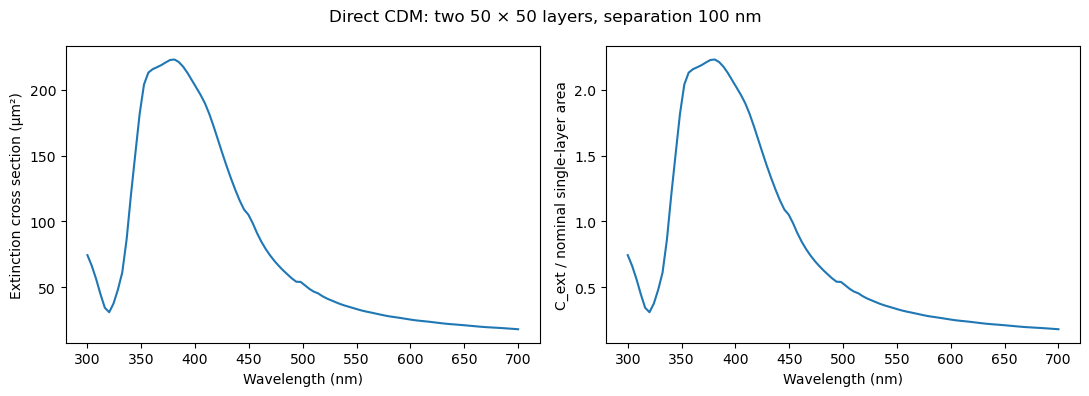

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(wavelength_nm, extinction_nm2 / 1e6)
axes[0].set(xlabel="Wavelength (nm)", ylabel="Extinction cross section (µm²)")
axes[1].plot(wavelength_nm, normalized_extinction)
axes[1].set(xlabel="Wavelength (nm)", ylabel="C_ext / nominal single-layer area")
fig.suptitle(f"Direct CDM: two {SIDE} × {SIDE} layers, separation {SEPARATION_NM:g} nm")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "extinction.png", dpi=180)
plt.show()

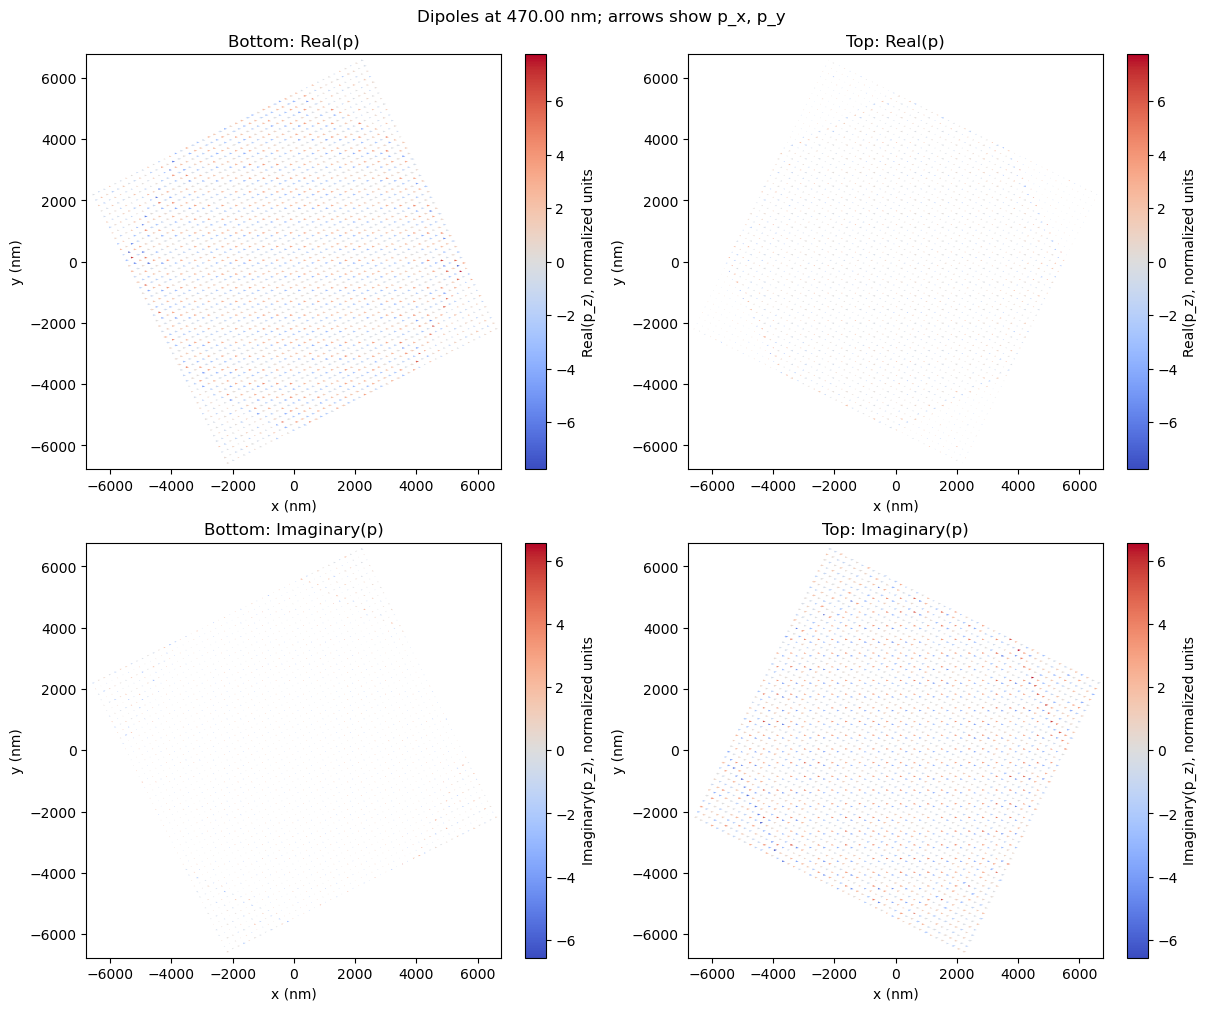

In [6]:
# Inspect all particles at a selected wavelength; adjust this value as needed.
DIPOLE_WAVELENGTH_NM = 470.0
iw = int(np.argmin(np.abs(wavelength_nm - DIPOLE_WAVELENGTH_NM)))
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
for column, (label, layer) in enumerate((
    ("Bottom", slice(0, particles_per_layer)),
    ("Top", slice(particles_per_layer, None)),
)):
    xy = positions_nm[layer, :2]
    for row, (part_label, values) in enumerate((
        ("Real", dipoles[iw, layer].real), ("Imaginary", dipoles[iw, layer].imag),
    )):
        ax = axes[row, column]
        all_values = dipoles[iw].real if row == 0 else dipoles[iw].imag
        scale = max(np.linalg.norm(all_values[:, :2], axis=1).max(), 1e-30) / (0.7 * SPACING_NM)
        limit = max(np.abs(all_values[:, 2]).max(), 1e-30)
        arrows = ax.quiver(
            xy[:, 0], xy[:, 1], values[:, 0], values[:, 1], values[:, 2],
            angles="xy", scale_units="xy", scale=scale, cmap="coolwarm",
            clim=(-limit, limit), width=max(0.0015, 0.02 / SIDE),
        )
        ax.set(aspect="equal", xlabel="x (nm)", ylabel="y (nm)", title=f"{label}: {part_label}(p)")
        ax.set_xlim(xy[:, 0].min() - SPACING_NM, xy[:, 0].max() + SPACING_NM)
        ax.set_ylim(xy[:, 1].min() - SPACING_NM, xy[:, 1].max() + SPACING_NM)
        fig.colorbar(arrows, ax=ax, label=f"{part_label}(p_z), normalized units")
fig.suptitle(f"Dipoles at {wavelength_nm[iw]:.2f} nm; arrows show p_x, p_y")
fig.savefig(OUTPUT_DIR / "dipoles.png", dpi=180)
plt.show()